## imports, set up and GPU optimisation

In [7]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
from pyspark.sql import SparkSession
from pyspark.sql.functions import col
from pyspark.sql.functions import mean, min, max
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus: 
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPU Available: []


## Spark data loading 

In [8]:
# Initialising Spark
spark = SparkSession.builder.appName("FashionMNIST_CNN").getOrCreate()

# Loading the CSV files of the dataset
train_spark = spark.read.csv("C:/Users/admin/mnist/fashion-mnist_train.csv", header=True, inferSchema=True)
test_spark = spark.read.csv("C:/Users/admin/mnist/fashion-mnist_test.csv", header=True, inferSchema=True)

## EDA
Exploratory Data Analysis
I have used Apache Spark for the data analysis phase as stated for us to do in the POE. Thus, the Fashion-MNIST CSV files need to be loaded into PySpark DataFrames, which the EDA should includes having a dataset that contains more than 10,000 records. Making sure there is no class imbalance. Computing the pixel statistics (min/max) in order to justify the normalisation step.

In [9]:
print("Basic Structure of the data")
print(f"Total Training Images: {train_spark.count()}")
print(f"Total Testing Images: {test_spark.count()}")
print(f"Number of columns (1 label + 784 pixels): {len(train_spark.columns)}")

Basic Structure of the data
Total Training Images: 60000
Total Testing Images: 10000
Number of columns (1 label + 784 pixels): 785


 Class Distribution 


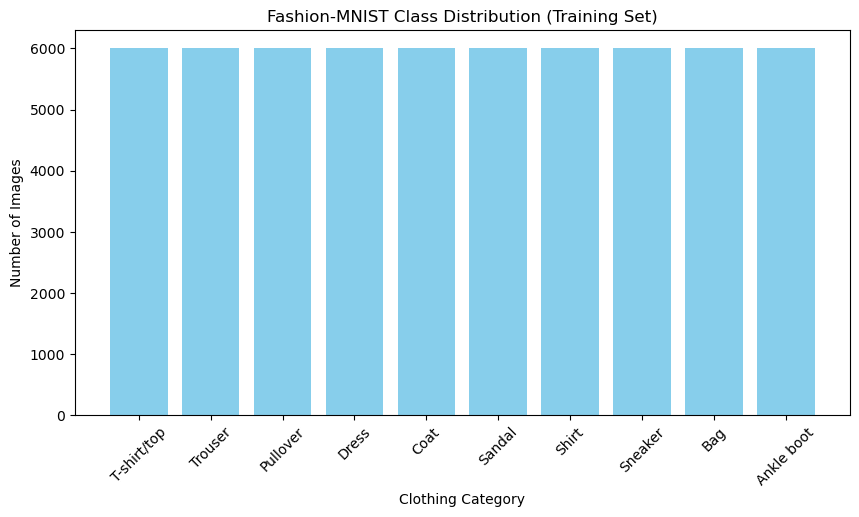

In [10]:
# Class Distribution
print(" Class Distribution ")
class_counts = train_spark.groupBy("label").count().orderBy("label").toPandas()

# Visualising the class balance 
plt.figure(figsize=(10, 5))
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
plt.bar(class_names, class_counts['count'], color='skyblue')
plt.title("Fashion-MNIST Class Distribution (Training Set)")
plt.xlabel("Clothing Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [11]:
# Spark-Based Pixel Statistics
print("Pixel Value Statistics")
# checking the stats of pixel1, pixel400 (center), and pixel784 (corner) using Spark
stats_df = train_spark.select(
    mean("pixel1").alias("Mean_pixel1"),
    min("pixel1").alias("Min_pixel1"),
    max("pixel1").alias("Max_pixel1"),
    mean("pixel400").alias("Mean_pixel400"),
    max("pixel400").alias("Max_pixel400")
)
stats_df.show()

Pixel Value Statistics
+-----------+----------+----------+-------------+------------+
|Mean_pixel1|Min_pixel1|Max_pixel1|Mean_pixel400|Max_pixel400|
+-----------+----------+----------+-------------+------------+
|     9.0E-4|         0|        16|     94.22505|         255|
+-----------+----------+----------+-------------+------------+



Visualising the Data


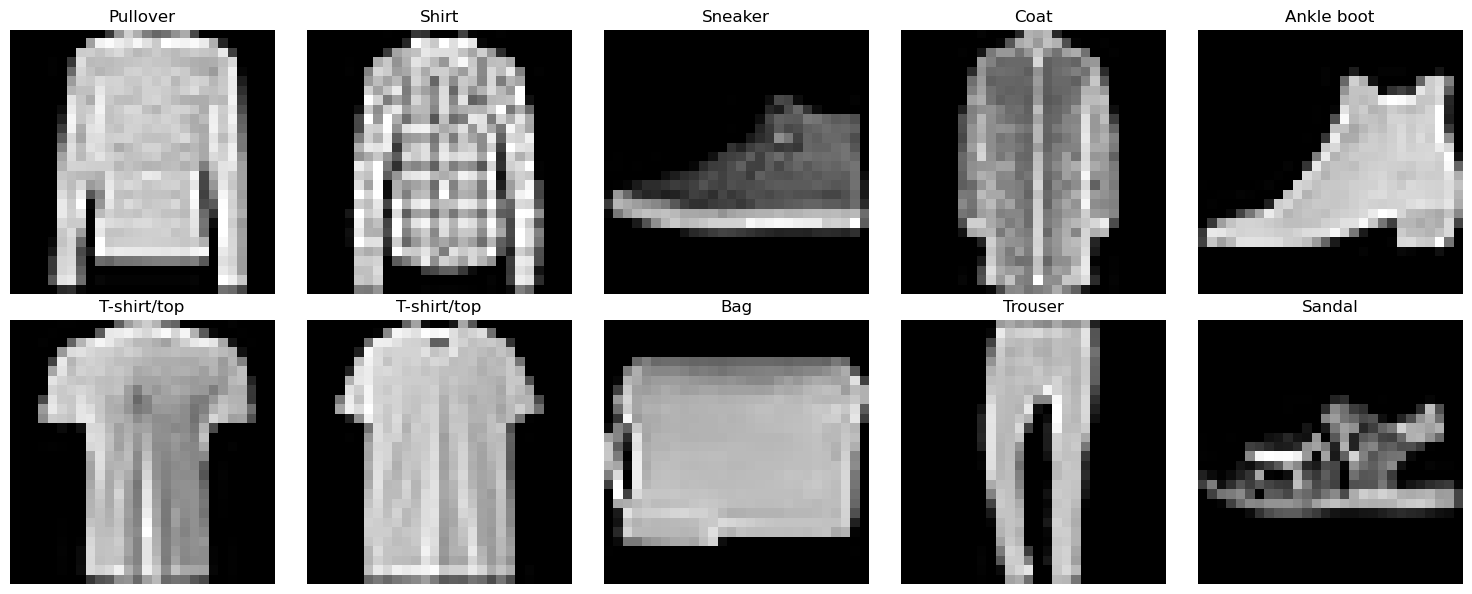

In [12]:
# Visualising a sample of images directly from the Spark DataFrame
print("Visualising the Data")
# Pulling 10 random images to Pandas just for plotting
sample_pd = train_spark.sample(False, 0.001, seed=42).limit(10).toPandas()

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
for i in range(10):
    # Droping the label, reshape the 784 pixels to 28x28, and plot
    img_pixels = sample_pd.drop('label', axis=1).iloc[i].values.reshape(28, 28)
    label_idx = sample_pd['label'].iloc[i]
    
    axes[i].imshow(img_pixels, cmap='gray')
    axes[i].set_title(class_names[label_idx])
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## Data Conversion and preprocessing 
As shown during the EDA process, pixel values range from 0 to 255, so to avoid the problem of vanishing gradients in training the CNN and to improve its training, the pixels will be normalised by dividing the pixels by 255.0. The flat 1D arrays of 784 pixels will be resized to 28x28x1 image tensors, and data will be transferred from PySpark to Pandas in order to make it compatible with TensorFlow.

In [14]:
# Converting  to pandas for temsorflow
train_pd = train_spark.toPandas()
test_pd = test_spark.toPandas()

y_train = train_pd.pop('label').values
X_train = train_pd.values.reshape(-1, 28, 28, 1) / 255.0

# Extracting labels and features for testing
y_test = test_pd.pop('label').values
X_test = test_pd.values.reshape(-1, 28, 28, 1) / 255.0

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (60000, 28, 28, 1)
X_test shape: (10000, 28, 28, 1)


## Training baseline model 
Feature Selection: Instead of using traditional feature selection techniques like P-values for images, convolutional neural networks utilise Conv2D layers to perform this step automatically. Conv2D layers extract spatial features such as edges and textures, while MaxPooling2D layers eliminating unnecessary pixel information. I am training a baseline CNN. The model has two convolutional layers followed by maxpooling. Adam optimiser and sparse categorical crossentropy are used as optimiser and loss function, respectively.

In [16]:
# Building a baseline CNN
model_1 = models.Sequential([
    layers.Input(shape=(28, 28, 1)), 
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_1.compile(optimizer='adam', 
                loss='sparse_categorical_crossentropy', 
                metrics=['accuracy'])

print("The Training Baseline Model")
# I will be using a 10% validation split to monitor overfitting
history_1 = model_1.fit(X_train, y_train, epochs=5, validation_split=0.1, batch_size=64)

# Evaluation
test_loss_1, test_acc_1 = model_1.evaluate(X_test, y_test)
print(f"\nBaseline Model Test Accuracy: {test_acc_1 * 100:.2f}%")

The Training Baseline Model
Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 27s 26ms/step - accuracy: 0.8090 - loss: 0.5247 - val_accuracy: 0.8558 - val_loss: 0.4128
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.8744 - loss: 0.3506 - val_accuracy: 0.8788 - val_loss: 0.3437
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.8895 - loss: 0.3039 - val_accuracy: 0.8940 - val_loss: 0.2959
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.8996 - loss: 0.2733 - val_accuracy: 0.8967 - val_loss: 0.2906
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9077 - loss: 0.2502 - val_accuracy: 0.9018 - val_loss: 0.2791
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9057 - loss: 0.2613

Baseline Model Test Accuracy: 90.57%


## Visualisation prediction of baseline
I visualise the predicted probabilities of classification of my baseline model using one sample test image to see its decision-making process and understand how confident it is about its predictions and accuracy in every class of clothing.

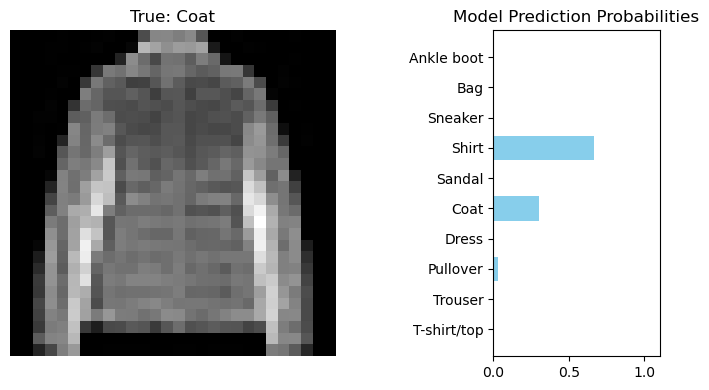

In [17]:
def view_classification(image, probabilities, true_label_index):
    fig, (ax1, ax2) = plt.subplots(figsize=(8, 4), ncols=2)
    
    ax1.imshow(image.reshape(28, 28), cmap='gray')
    ax1.set_title(f"True: {class_names[true_label_index]}")
    ax1.axis('off')
    
    # Showing probabilities
    ax2.barh(np.arange(10), probabilities, color='skyblue')
    ax2.set_aspect(0.2)
    ax2.set_yticks(np.arange(10))
    ax2.set_yticklabels(class_names)
    ax2.set_title('Model Prediction Probabilities')
    ax2.set_xlim(0, 1.1)
    plt.tight_layout()
    plt.show()

# Testing on a random image from the test set
index = 42 
image = X_test[index]
true_label = y_test[index]
probs = model_1.predict(image.reshape(1, 28, 28, 1), verbose=0)[0]

view_classification(image, probs, true_label)

## Train Improved Model
The baseline model achieved about 90% accuracy, but the CNN models may be prone to overfitting on training data, so for that reason, I will retrain my model with two improvements by these methods, Data Augmentation which means using some transformations such as random rotations, zooms, and horizontal flips of images to increase the data size, and training the model to recognise generalised shape features. Another way was the dropout layer, which is randomly disabling some nodes in the neural network during the training process, and lastly, early stopping which is monitoring validation loss to stop the training at the moment the accuracy started to decrease

In [18]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping

# Set up Data Augmentation
datagen = ImageDataGenerator(
    rotation_range=10,      
    width_shift_range=0.1,  
    height_shift_range=0.1, 
    horizontal_flip=True    
)
datagen.fit(X_train)

# Building Improved Model
model_2 = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3), # New: Dropout to prevent overfitting
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # New: Dropout to prevent overfitting
    layers.Dense(10, activation='softmax')
])

model_2.compile(optimizer='adam', 
                loss='sparse_categorical_crossentropy', 
                metrics=['accuracy'])

# Training using Early Stopping
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

print("Training Improved Model")
history_2 = model_2.fit(datagen.flow(X_train, y_train, batch_size=64), 
                        epochs=15, 
                        validation_data=(X_test, y_test),
                        callbacks=[early_stop])

test_loss_2, test_acc_2 = model_2.evaluate(X_test, y_test)
print(f"\nImproved Model Test Accuracy: {test_acc_2 * 100:.2f}%")

C:\Users\admin\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training Improved Model
Epoch 1/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 94s 81ms/step - accuracy: 0.6893 - loss: 0.8354 - val_accuracy: 0.7913 - val_loss: 0.5151
Epoch 2/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 63s 67ms/step - accuracy: 0.7674 - loss: 0.6211 - val_accuracy: 0.8284 - val_loss: 0.4512
Epoch 3/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 86s 91ms/step - accuracy: 0.7900 - loss: 0.5590 - val_accuracy: 0.8430 - val_loss: 0.4212
Epoch 4/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 70s 75ms/step - accuracy: 0.8066 - loss: 0.5199 - val_accuracy: 0.8669 - val_loss: 0.3600
Epoch 5/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 85ms/step - accuracy: 0.8189 - loss: 0.4929 - val_accuracy: 0.8687 - val_loss: 0.3489
Epoch 6/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 75s 78ms/step - accuracy: 0.8255 - loss: 0.4718 - val_accuracy: 0.8787 - val_loss: 0.3304
Epoch 7/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 67s 71ms/step - accuracy: 0.8316 - loss: 0.4548 - val_accuracy: 0.8738 - val_loss: 0.3376
Epoch 8/15
938/938 ━━━━━━━━━━━━━━━━━━━━ 88s 94ms/step - accuracy: 

## Final evaluation
As the final step, a confusion matrix is constructed which precisely shows the clothing categories for which the improved model faces difficulties to classify.

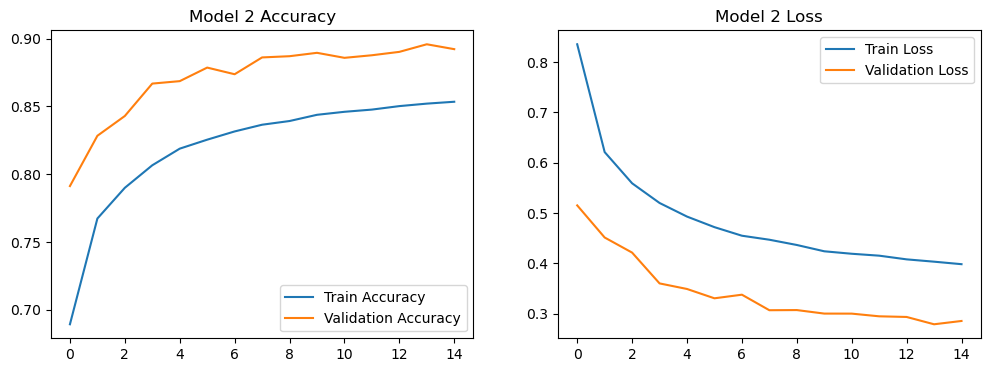

In [19]:
# Ploting the Learning Curve
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_2.history['accuracy'], label='Train Accuracy')
plt.plot(history_2.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model 2 Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_2.history['loss'], label='Train Loss')
plt.plot(history_2.history['val_loss'], label='Validation Loss')
plt.title('Model 2 Loss')
plt.legend()
plt.show()

## Confusion matrix

Confusion Matrix
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


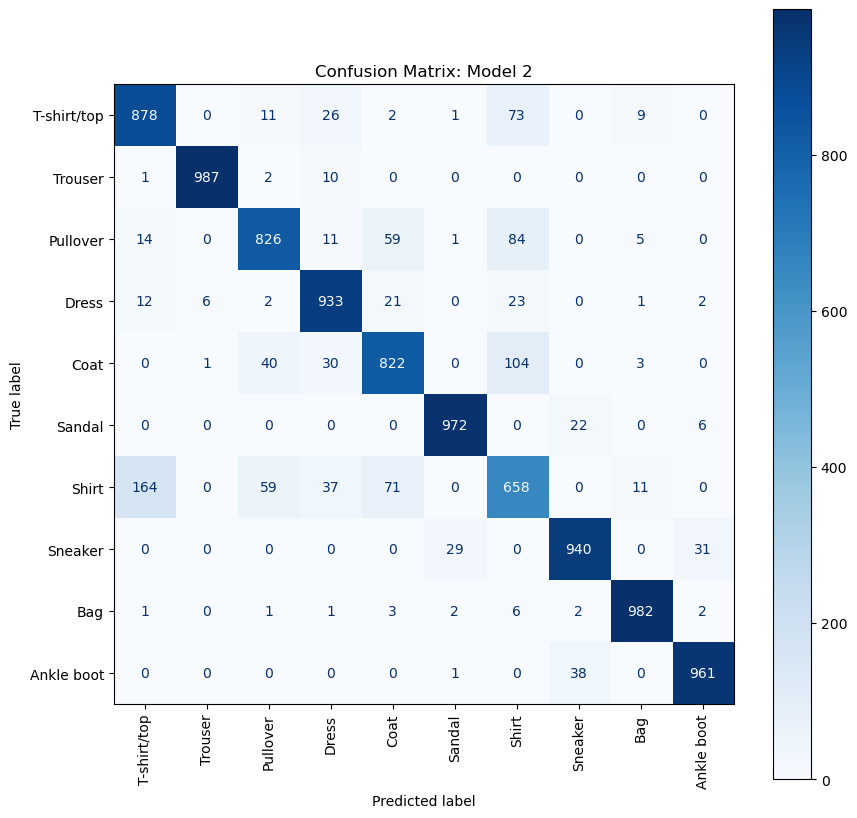

In [21]:
print("Confusion Matrix")
y_pred_probs = model_2.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(cmap='Blues', ax=ax, xticks_rotation='vertical')
plt.title("Confusion Matrix: Model 2")
plt.show()